In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("StudentPerformanceFactors.csv")
print(df.shape)
df.head()

(6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

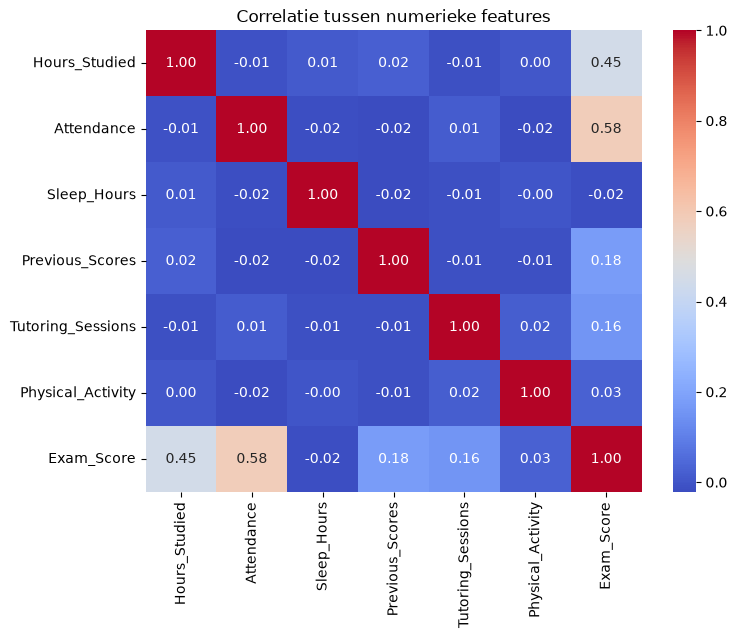

In [3]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlatie tussen numerieke features")
plt.show()

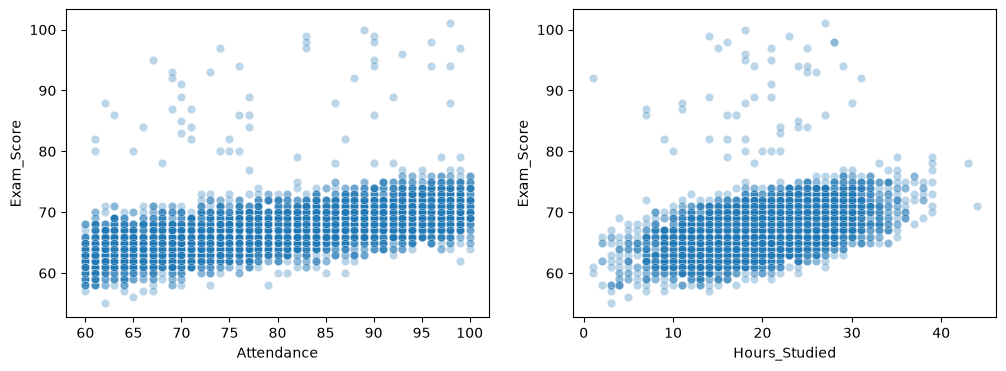

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="Attendance", y="Exam_Score", alpha=0.3, ax=axes[0])
sns.scatterplot(data=df, x="Hours_Studied", y="Exam_Score", alpha=0.3, ax=axes[1])
plt.show()

In [5]:
df = df[df["Exam_Score"] <= 100]   # onmogelijke score verwijderen
df = df.dropna()                   # rijen met lege waarden verwijderen

# Tekst naar getallen (alleen de kolommen die we gebruiken)
df["Family_Income"] = df["Family_Income"].map({"Low": 0, "Medium": 1, "High": 2})
df["Gender"] = df["Gender"].map({"Male": 0, "Female": 1})
df["Learning_Disabilities"] = df["Learning_Disabilities"].map({"No": 0, "Yes": 1})
df["Parental_Education_Level"] = df["Parental_Education_Level"].map(
    {"High School": 0, "College": 1, "Postgraduate": 2})

print(df.shape)   # verwacht: (6377, 20)

(6377, 20)


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

features_goed = ["Attendance", "Hours_Studied", "Previous_Scores", "Tutoring_Sessions"]
features_kwaad = features_goed + ["Family_Income", "Gender",
                                  "Parental_Education_Level", "Learning_Disabilities"]
y = df["Exam_Score"]

In [7]:
def train_model(features):
    X = df[features]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)   # fit alleen op trainingsdata
    X_test_s = scaler.transform(X_test)

    model = MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=2000,
                         early_stopping=True, random_state=42)
    model.fit(X_train_s, y_train)

    pred = model.predict(X_test_s)
    baseline = np.full(len(y_test), y_train.mean())   # altijd het gemiddelde voorspellen
    print(f"MAE model:    {mean_absolute_error(y_test, pred):.2f}")
    print(f"MAE baseline: {mean_absolute_error(y_test, baseline):.2f}")
    print(f"R²:           {r2_score(y_test, pred):.3f}")
    return model, scaler, X_train

In [8]:
print("StudieKompas (4 features)")
model_goed, scaler_goed, X_train_goed = train_model(features_goed)
print("\nSlimScore (8 features)")
model_kwaad, scaler_kwaad, X_train_kwaad = train_model(features_kwaad)

StudieKompas (4 features)
MAE model:    1.42
MAE baseline: 2.85
R²:           0.582

SlimScore (8 features)
MAE model:    1.28
MAE baseline: 2.85
R²:           0.614


In [9]:
daan = pd.DataFrame([{"Attendance": 72, "Hours_Studied": 12,
                      "Previous_Scores": 64, "Tutoring_Sessions": 0}])
print("Daan nu:", model_goed.predict(scaler_goed.transform(daan))[0].round(1))

for kolom, nieuw in [("Attendance", 95), ("Hours_Studied", 20), ("Tutoring_Sessions", 3)]:
    test = daan.copy()
    test[kolom] = nieuw
    print(f"{kolom} -> {nieuw}:", model_goed.predict(scaler_goed.transform(test))[0].round(1))

Daan nu: 62.0
Attendance -> 95: 66.4
Hours_Studied -> 20: 64.6
Tutoring_Sessions -> 3: 63.8


In [10]:
joblib.dump(model_goed, "studiekompas_model.pkl")
joblib.dump(scaler_goed, "studiekompas_scaler.pkl")
joblib.dump(model_kwaad, "slimscore_model.pkl")
joblib.dump(scaler_kwaad, "slimscore_scaler.pkl")
joblib.dump(X_train_goed.sample(100, random_state=42), "studiekompas_achtergrond.pkl")  # nodig voor SHAP
print("Opgeslagen!")

Opgeslagen!
